<a href="https://colab.research.google.com/github/HarisJafri-xcode/Data-Analyst-in-Python/blob/main/Data-Manipulation-with-Pandas/Creating_and_Visualizing_DataFrame.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Visualizing your data

In [ ]:
# Importing Important DS Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Loading Dataframe
file_path = 'https://raw.githubusercontent.com/HarisJafri-xcode/Python-Session-DataSets/refs/heads/main/Data_Manipulation/avocados.pkl'
avocados = pd.read_pickle(file_path)

In [ ]:
# First Few Rows of the DataFrame
avocados.head()

,date,type,year,avg_price,size,nb_sold
0,2015-12-27,conventional,2015,0.95,small,9626901.09
1,2015-12-20,conventional,2015,0.98,small,8710021.76
2,2015-12-13,conventional,2015,0.93,small,9855053.66
3,2015-12-06,conventional,2015,0.89,small,9405464.36
4,2015-11-29,conventional,2015,0.99,small,8094803.56


In [ ]:
# Grouping by size and summing nb_sold
nb_sold_by_size = avocados.groupby('size')['nb_sold'].sum()

In [ ]:
# What dtype is this ?
type(nb_sold_by_size)

pandas.core.series.Series

In [ ]:
# Observing Data Series
nb_sold_by_size

,nb_sold
size,
extra_large,1.561752e+08
large,2.015012e+09
small,2.054936e+09


<Axes: xlabel='size'>

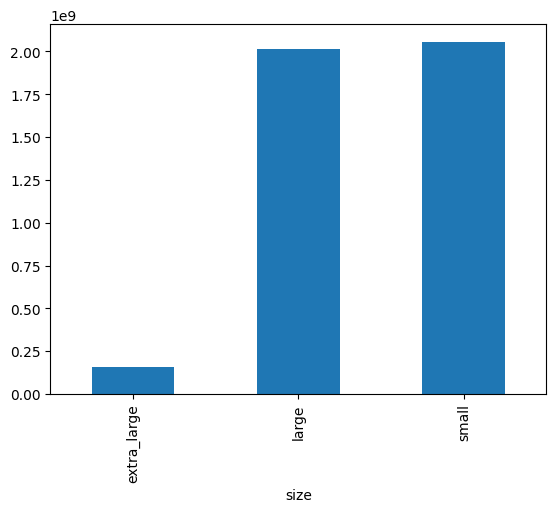

In [ ]:
# Pandas Data Series can be plotted
nb_sold_by_size.plot(kind="bar")

<Axes: xlabel='date'>

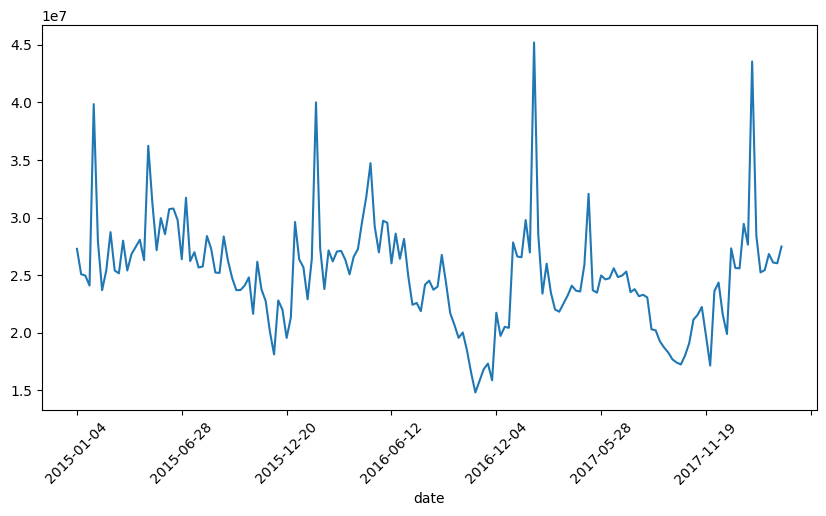

In [ ]:
# total number of avocados sold on each date.
nb_sold_by_date = avocados.groupby('date')['nb_sold'].sum()
nb_sold_by_date.plot(kind="line", figsize=(10, 5), rot=45)

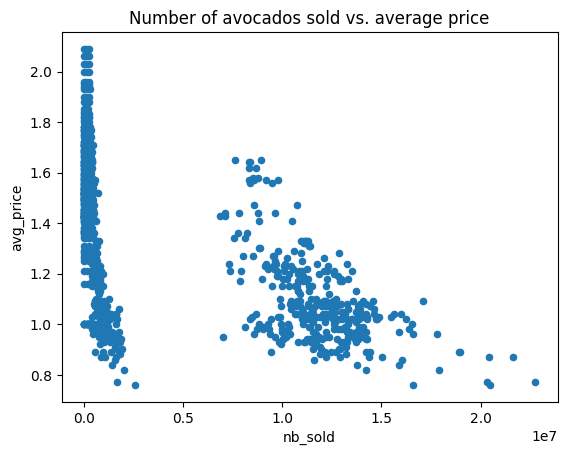

In [ ]:
# is nb_sold related to avg_price
avocados.plot(kind='scatter',x='nb_sold',y='avg_price',title="Number of avocados sold vs. average price")
plt.show()

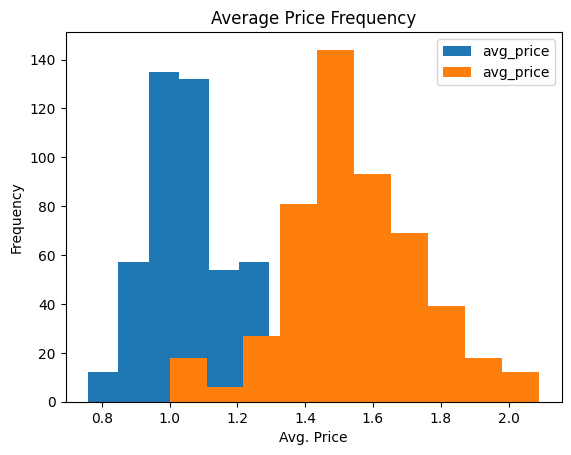

In [ ]:
# Distribution of avg_price for Conventional and Organic
avocados[avocados['type'] == 'conventional']['avg_price'].plot(kind='hist',legend=True)
avocados[avocados['type'] == 'organic']['avg_price'].plot(kind='hist',legend=True)
plt.title('Average Price Frequency')
plt.xlabel('Avg. Price')
plt.ylabel('Frequency')
plt.show()

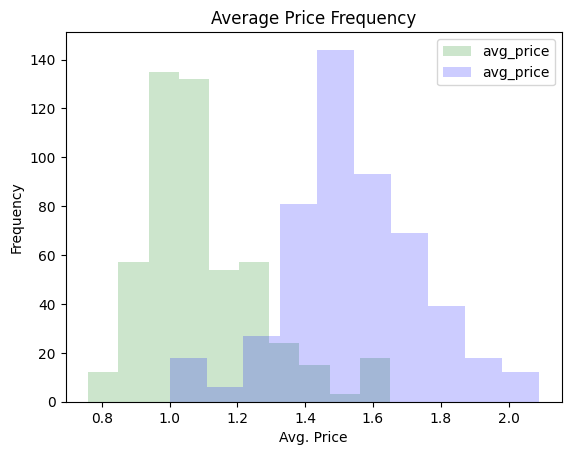

In [ ]:
# Distribution of avg_price for Conventional and Organic again
avocados[avocados['type'] == 'conventional']['avg_price'].plot(kind='hist',legend=True, alpha=0.2, color="Green")
avocados[avocados['type'] == 'organic']['avg_price'].plot(kind='hist',legend=True, alpha=0.2, color="Blue")
plt.title('Average Price Frequency')
plt.xlabel('Avg. Price')
plt.ylabel('Frequency')
plt.show()

In [ ]:
# finding what can be done with .plot
# help(avocados.plot) <--- Commented to avoid long output

In [ ]:
# Digging further
# help(plt.hist) <--- Commented to avoid long output

# Missing Values

In [ ]:
# Loading avocados sale dataset from 2016
file_path_2016 = 'https://raw.githubusercontent.com/HarisJafri-xcode/Python-Session-DataSets/refs/heads/main/Data_Manipulation/avocados_2016.csv'
avocados_2016 = pd.read_csv(file_path_2016)

In [ ]:
# Which value is missing
avocados_2016.isna().head()

,date,avg_price,total_sold,small_sold,large_sold,xl_sold,total_bags_sold,small_bags_sold,large_bags_sold,xl_bags_sold
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,True,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,True,False,False,False,False


In [ ]:
# Which Column contains missing Value
avocados_2016.isna().any()

,0
date,False
avg_price,False
total_sold,False
small_sold,True
large_sold,True
xl_sold,True
total_bags_sold,False
small_bags_sold,False
large_bags_sold,False
xl_bags_sold,False


In [ ]:
# Which Column contains how many missing Value
avocados_2016.isna().sum()

,0
date,0
avg_price,0
total_sold,0
small_sold,6
large_sold,6
xl_sold,4
total_bags_sold,0
small_bags_sold,0
large_bags_sold,0
xl_bags_sold,0


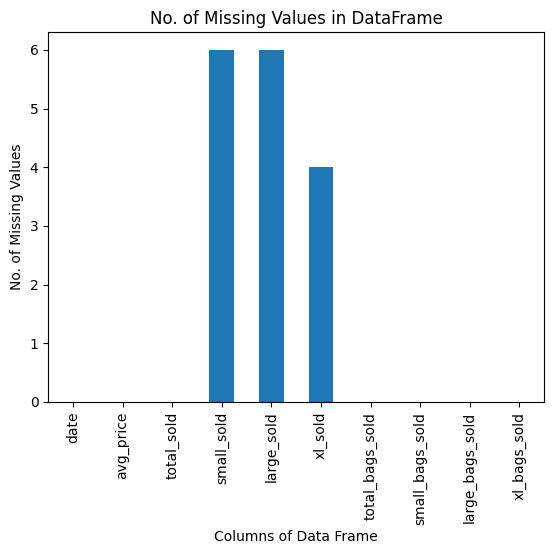

In [ ]:
# Plotting Data Series
avocados_2016.isna().sum().plot(kind='bar')
plt.xlabel('Columns of Data Frame')
plt.ylabel('No. of Missing Values')
plt.title('No. of Missing Values in DataFrame')
plt.show()

In [ ]:
# Drop Rows that contain missing Values
avocados_complete = avocados_2016.dropna()
avocados_complete.isna().sum()

,0
date,0
avg_price,0
total_sold,0
small_sold,0
large_sold,0
xl_sold,0
total_bags_sold,0
small_bags_sold,0
large_bags_sold,0
xl_bags_sold,0


In [ ]:
cols_with_missing = ["small_sold", "large_sold", "xl_sold"]

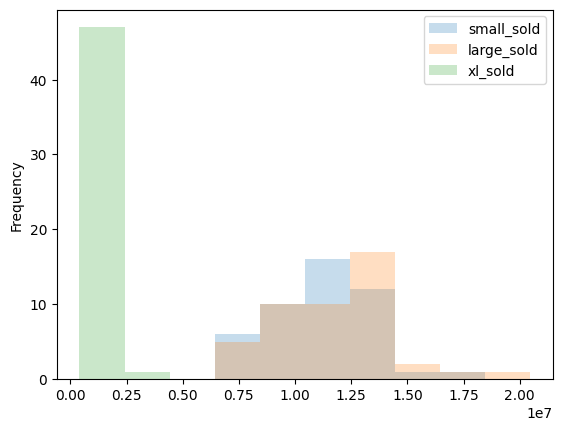

In [ ]:
avocados_2016[cols_with_missing].plot(kind='hist',alpha=0.25)
plt.show()

In [ ]:
# Imputing
avocados_filled = avocados_2016.fillna(0)

# Checking the Column
avocados_filled.isna().sum()

,0
date,0
avg_price,0
total_sold,0
small_sold,0
large_sold,0
xl_sold,0
total_bags_sold,0
small_bags_sold,0
large_bags_sold,0
xl_bags_sold,0


# Creating Dataframes

In [ ]:
# Create a dictionary of lists

avocados_dict = {
  "date": ["2019-11-17","2019-12-01"],
  "small_sold": [10859987,9291631],
  "large_sold": [7674135,6238096]
}

In [ ]:
# Convert dictionary into DataFrame
avocados_2019 = pd.DataFrame(avocados_dict)

In [ ]:
# Viewing Dataframe
avocados_2019

,date,small_sold,large_sold
0,2019-11-17,10859987,7674135
1,2019-12-01,9291631,6238096


In [ ]:
avocados_2019.to_csv("avocados_2019.csv")